
# **Experiment 3**
## **Audio Data Preprocessing: To preprocess audio data by extracting features such as MFCCs and applying noise reduction**

**Name:** Sneha Roychowdhury  
**Branch/Section:** ECE-AI (2)  
**Semester:** 7  
**Subject:** Multimodal Data Analysis  

---

### Aim
To preprocess an UrbanSound8K audio signal by studying its duration, sampling rate, waveform shape and frequency characteristics; apply noise reduction; compare the original and processed audio; extract MFCC features; visualize and inspect sample values; and save the extracted features for future audio/sound recognition tasks.

### Main Tasks
1. Load an audio file from UrbanSound8K.
2. Analyze signal duration, sampling rate, waveform and frequency-domain characteristics.
3. Apply noise reduction.
4. Compare original and noise-reduced signals using waveforms, spectra and spectrograms.
5. Extract MFCC features.
6. Visualize MFCCs and display sample numerical values.
7. Save processed audio and extracted features for later classification/recognition tasks.

### Dataset
**UrbanSound8K:** https://urbansounddataset.weebly.com/urbansound8k.html

UrbanSound8K contains **8,732 labeled WAV excerpts** (up to approximately 4 seconds) from **10 urban sound classes**, organized into predefined folds. The original files can have different sampling rates, bit depths and channel counts. For later model evaluation, the official dataset documentation recommends preserving the predefined folds.


## **Step 0 — Install Required Libraries**

The notebook uses:
- **soundata** for the official UrbanSound8K download/loader workflow.
- **librosa** for audio loading, resampling, spectral analysis and MFCC extraction.
- **noisereduce** for spectral-gating-based noise reduction.
- **soundfile** for saving processed WAV files.


In [1]:

!pip -q install soundata librosa noisereduce soundfile tqdm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.0/162.0 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.3/67.3 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.2/72.2 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 492.7/492.7 kB 42.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.8/102.8 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.4/52.4 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 144.5/144.5 kB 15.8 MB/s eta 0:00:00


## **Step 1 — Import Libraries and Set Experiment Parameters**

In [2]:

import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
import noisereduce as nr
import soundata

from IPython.display import Audio, display
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
np.random.seed(42)

# -----------------------------
# Experiment configuration
# -----------------------------
DATA_HOME = "/content/urbansound8k_data"
OUTPUT_DIR = Path("/content/experiment3_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_SR = 22050       # fixed sampling rate used for MFCC extraction
N_MFCC = 20
N_FFT = 2048
HOP_LENGTH = 512

print("Output directory:", OUTPUT_DIR)


Output directory: /content/experiment3_outputs



## **Step 2 — Download / Initialize UrbanSound8K**

The official UrbanSound8K page supports downloading through the `soundata` Python package.

> **Note:** UrbanSound8K is a large dataset (several GB). The following cell downloads the full dataset into the Colab runtime. If the files are already present in `DATA_HOME`, rerunning the notebook will reuse them.


In [3]:

dataset = soundata.initialize("urbansound8k", data_home=DATA_HOME)

# Download the official dataset. soundata reuses files that already exist.
dataset.download()

print("UrbanSound8K initialized successfully.")
print("Number of clip IDs in index:", len(dataset.clip_ids))


5.61GB [07:07, 14.1MB/s]                            
1.15MB [00:02, 551kB/s]                            

UrbanSound8K initialized successfully.
Number of clip IDs in index: 8732


## **Step 3 — Select and Load One Audio File**

In [4]:

# Pick a deterministic example clip.
sample_clip_id = dataset.clip_ids[0]
sample_clip = dataset.clip(sample_clip_id)

audio_path = sample_clip.audio_path
class_label = sample_clip.class_label
class_id = sample_clip.class_id
fold = sample_clip.fold

# Load at the file's native sampling rate.
y, sr = librosa.load(audio_path, sr=None, mono=True)

duration = librosa.get_duration(y=y, sr=sr)

print("Clip ID       :", sample_clip_id)
print("Audio path    :", audio_path)
print("Class label   :", class_label)
print("Class ID      :", class_id)
print("Fold          :", fold)
print("Sampling rate :", sr, "Hz")
print("Duration      :", round(duration, 4), "seconds")
print("Waveform shape:", y.shape)
print("No. of samples:", len(y))
print("Data type     :", y.dtype)

print("\nOriginal audio:")
display(Audio(y, rate=sr))


Clip ID       : 135776-2-0-49
Audio path    : /content/urbansound8k_data/audio/fold1/135776-2-0-49.wav
Class label   : children_playing
Class ID      : 2
Fold          : 1
Sampling rate : 48000 Hz
Duration      : 4.0 seconds
Waveform shape: (192000,)
No. of samples: 192000
Data type     : float32

Original audio:


## **Step 4 — Analyze Signal Duration, Sampling Rate and Waveform Shape**

In [5]:

signal_summary = pd.DataFrame({
    "Property": [
        "Duration (s)",
        "Sampling rate (Hz)",
        "Number of samples",
        "Waveform shape",
        "Minimum amplitude",
        "Maximum amplitude",
        "Mean amplitude",
        "RMS amplitude"
    ],
    "Value": [
        duration,
        sr,
        len(y),
        str(y.shape),
        float(np.min(y)),
        float(np.max(y)),
        float(np.mean(y)),
        float(np.sqrt(np.mean(y ** 2)))
    ]
})

display(signal_summary)


,Property,Value
0,Duration (s),4.0
1,Sampling rate (Hz),48000
2,Number of samples,192000
3,Waveform shape,"(192000,)"
4,Minimum amplitude,-0.065909
5,Maximum amplitude,0.077856
6,Mean amplitude,0.000001
7,RMS amplitude,0.009362


### Original Waveform

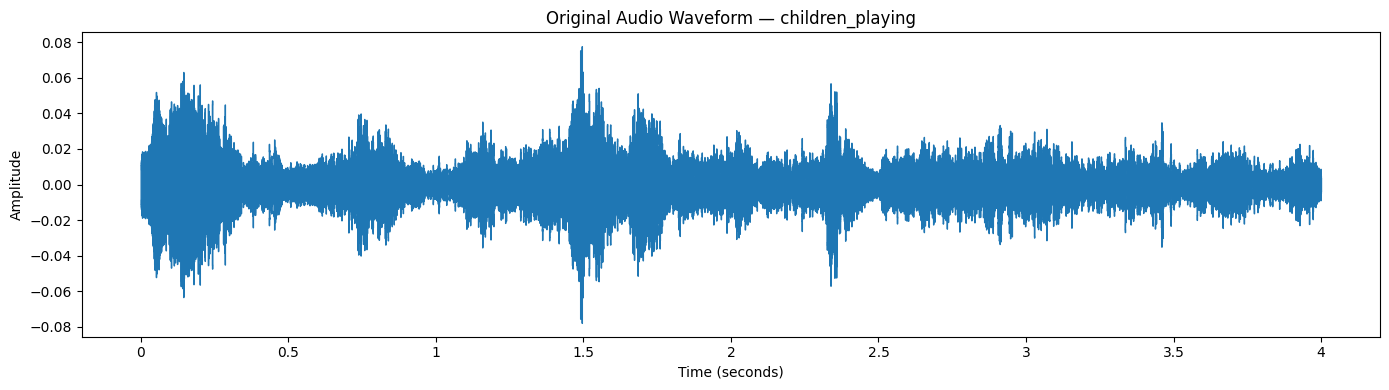

In [6]:

plt.figure(figsize=(14, 4))
librosa.display.waveshow(y, sr=sr)
plt.title(f"Original Audio Waveform — {class_label}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()



### Interpretation
The waveform shows how signal amplitude changes with time. Large peaks correspond to stronger acoustic events, while low-amplitude portions may contain silence, background noise, or weaker sound components.


## **Step 5 — Analyze Frequency Characteristics**

In [7]:

def spectral_statistics(signal, sample_rate):
    centroid = librosa.feature.spectral_centroid(y=signal, sr=sample_rate).mean()
    bandwidth = librosa.feature.spectral_bandwidth(y=signal, sr=sample_rate).mean()
    rolloff = librosa.feature.spectral_rolloff(y=signal, sr=sample_rate, roll_percent=0.85).mean()
    zcr = librosa.feature.zero_crossing_rate(signal).mean()
    return centroid, bandwidth, rolloff, zcr

centroid, bandwidth, rolloff, zcr = spectral_statistics(y, sr)

freq_stats = pd.DataFrame({
    "Metric": [
        "Mean spectral centroid (Hz)",
        "Mean spectral bandwidth (Hz)",
        "Mean 85% spectral roll-off (Hz)",
        "Mean zero-crossing rate"
    ],
    "Original Audio": [
        centroid, bandwidth, rolloff, zcr
    ]
})

display(freq_stats.round(4))


,Metric,Original Audio
0,Mean spectral centroid (Hz),2218.5361
1,Mean spectral bandwidth (Hz),2140.6571
2,Mean 85% spectral roll-off (Hz),4116.5226
3,Mean zero-crossing rate,0.0622


### FFT Magnitude Spectrum

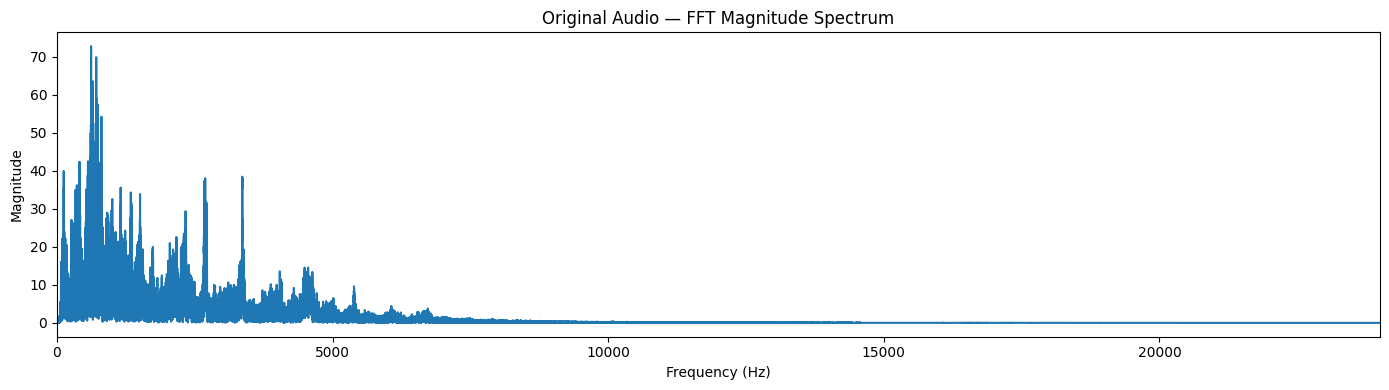

In [8]:

# Real-valued FFT
fft_values = np.fft.rfft(y)
fft_freqs = np.fft.rfftfreq(len(y), d=1/sr)
magnitude = np.abs(fft_values)

plt.figure(figsize=(14, 4))
plt.plot(fft_freqs, magnitude)
plt.title("Original Audio — FFT Magnitude Spectrum")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, sr / 2)
plt.tight_layout()
plt.show()


### Original Spectrogram

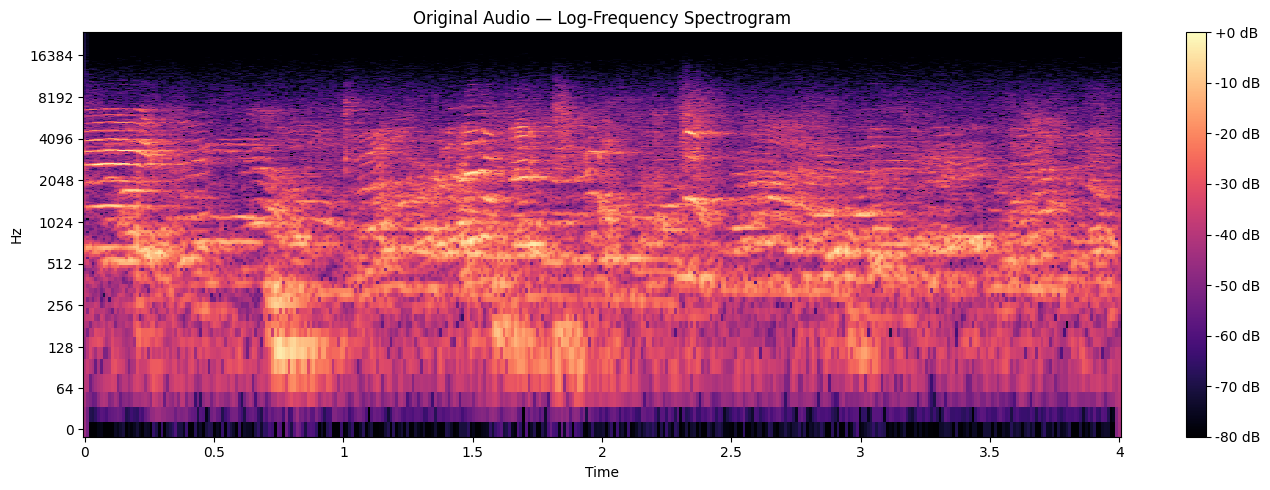

In [9]:

stft_original = librosa.stft(y, n_fft=N_FFT, hop_length=HOP_LENGTH)
db_original = librosa.amplitude_to_db(np.abs(stft_original), ref=np.max)

plt.figure(figsize=(14, 5))
librosa.display.specshow(
    db_original,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="log"
)
plt.colorbar(format="%+2.0f dB")
plt.title("Original Audio — Log-Frequency Spectrogram")
plt.tight_layout()
plt.show()



## **Step 6 — Apply Noise Reduction**

We use the `noisereduce` library, which applies a spectral-gating approach. The algorithm estimates unwanted spectral components and attenuates them while attempting to retain the dominant sound event.

`prop_decrease=0.8` performs noticeable but not fully aggressive suppression, which helps avoid removing too much useful signal.


In [10]:

y_reduced = nr.reduce_noise(
    y=y,
    sr=sr,
    stationary=False,
    prop_decrease=0.8
).astype(np.float32)

# Keep length identical to the original signal.
y_reduced = librosa.util.fix_length(y_reduced, size=len(y))

print("Noise-reduced waveform shape:", y_reduced.shape)
print("Noise-reduced audio:")
display(Audio(y_reduced, rate=sr))


Noise-reduced waveform shape: (192000,)
Noise-reduced audio:


## **Step 7 — Compare Original and Noise-Reduced Audio**

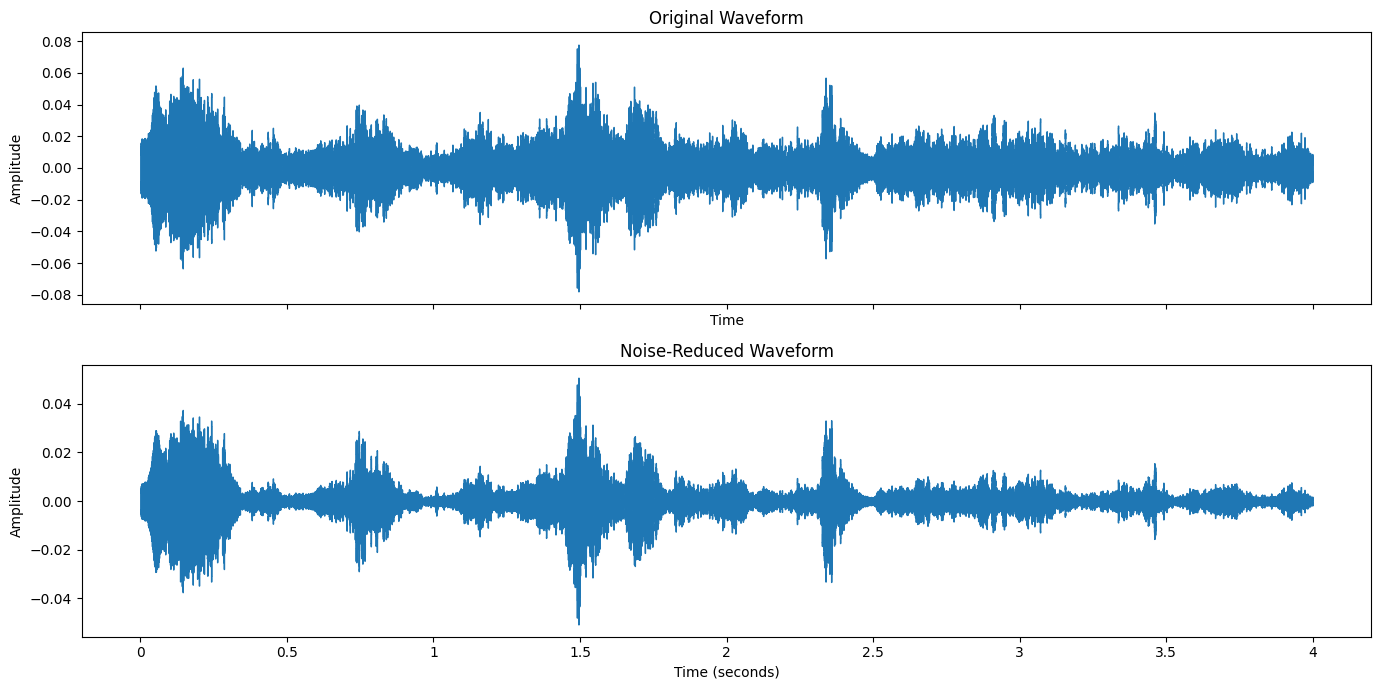

In [11]:

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

librosa.display.waveshow(y, sr=sr, ax=axes[0])
axes[0].set_title("Original Waveform")
axes[0].set_ylabel("Amplitude")

librosa.display.waveshow(y_reduced, sr=sr, ax=axes[1])
axes[1].set_title("Noise-Reduced Waveform")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude")

plt.tight_layout()
plt.show()


### Compare Frequency Spectra

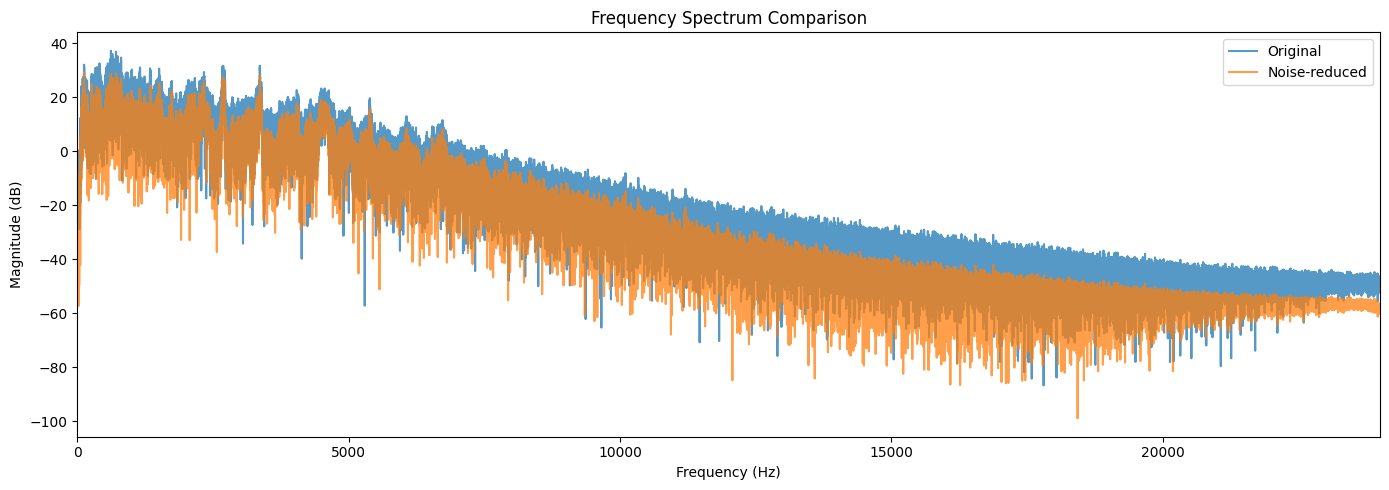

In [12]:

fft_original = np.abs(np.fft.rfft(y))
fft_reduced = np.abs(np.fft.rfft(y_reduced))
freqs = np.fft.rfftfreq(len(y), d=1/sr)

# Convert to dB-like scale for easier visual comparison.
eps = 1e-10
original_db = 20 * np.log10(fft_original + eps)
reduced_db = 20 * np.log10(fft_reduced + eps)

plt.figure(figsize=(14, 5))
plt.plot(freqs, original_db, label="Original", alpha=0.75)
plt.plot(freqs, reduced_db, label="Noise-reduced", alpha=0.75)
plt.title("Frequency Spectrum Comparison")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(0, sr / 2)
plt.legend()
plt.tight_layout()
plt.show()


### Compare Spectrograms

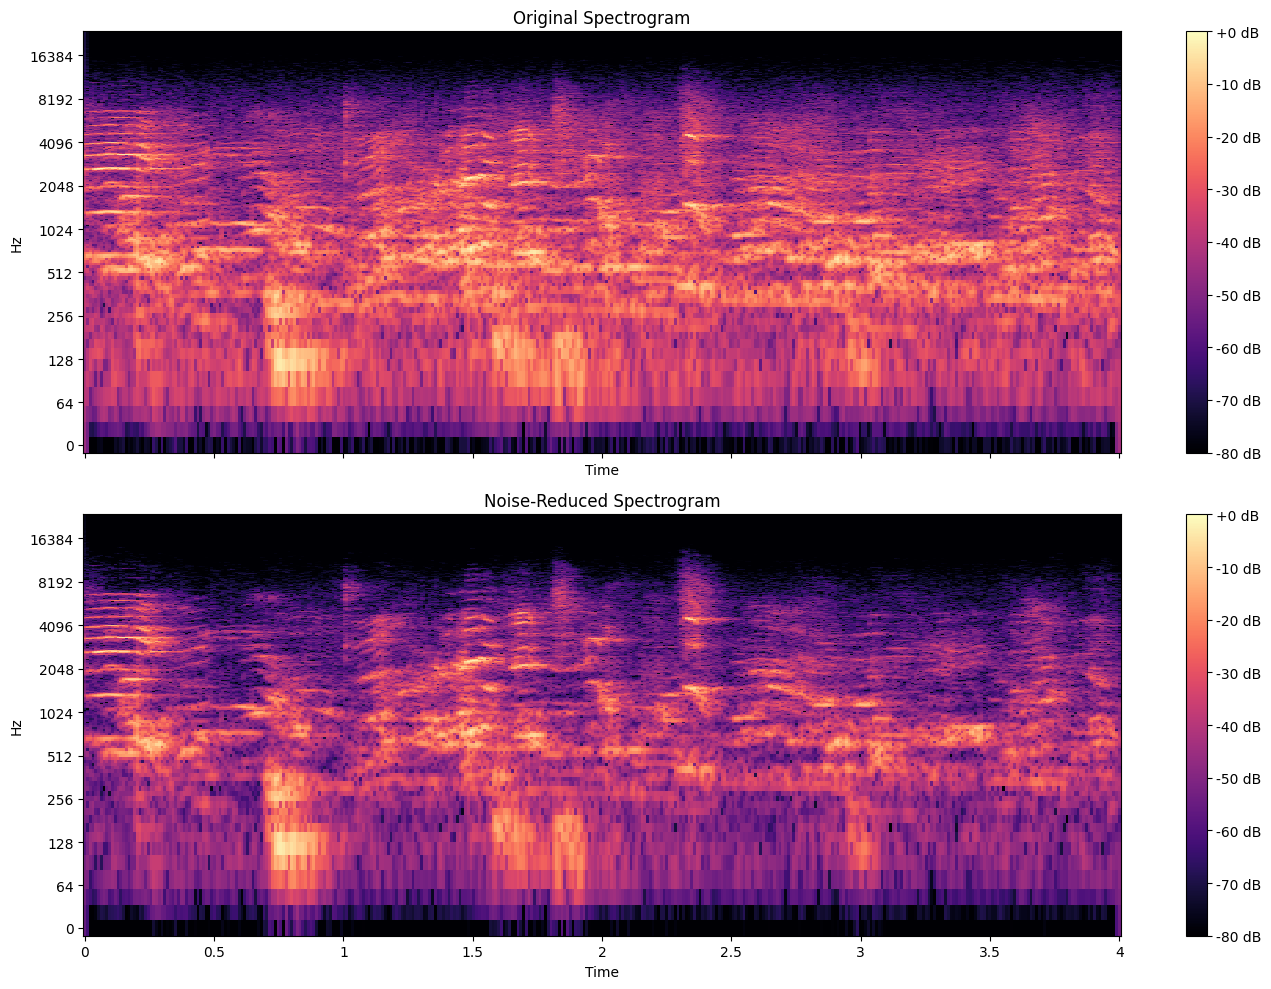

In [13]:

stft_reduced = librosa.stft(y_reduced, n_fft=N_FFT, hop_length=HOP_LENGTH)
db_reduced = librosa.amplitude_to_db(np.abs(stft_reduced), ref=np.max)

fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

img1 = librosa.display.specshow(
    db_original,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="log",
    ax=axes[0]
)
axes[0].set_title("Original Spectrogram")
fig.colorbar(img1, ax=axes[0], format="%+2.0f dB")

img2 = librosa.display.specshow(
    db_reduced,
    sr=sr,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="log",
    ax=axes[1]
)
axes[1].set_title("Noise-Reduced Spectrogram")
fig.colorbar(img2, ax=axes[1], format="%+2.0f dB")

plt.tight_layout()
plt.show()


### Quantitative Comparison Before and After Noise Reduction

In [14]:

orig_centroid, orig_bandwidth, orig_rolloff, orig_zcr = spectral_statistics(y, sr)
red_centroid, red_bandwidth, red_rolloff, red_zcr = spectral_statistics(y_reduced, sr)

comparison_table = pd.DataFrame({
    "Metric": [
        "RMS amplitude",
        "Peak amplitude",
        "Spectral centroid (Hz)",
        "Spectral bandwidth (Hz)",
        "85% spectral roll-off (Hz)",
        "Zero-crossing rate"
    ],
    "Original": [
        np.sqrt(np.mean(y ** 2)),
        np.max(np.abs(y)),
        orig_centroid,
        orig_bandwidth,
        orig_rolloff,
        orig_zcr
    ],
    "Noise-reduced": [
        np.sqrt(np.mean(y_reduced ** 2)),
        np.max(np.abs(y_reduced)),
        red_centroid,
        red_bandwidth,
        red_rolloff,
        red_zcr
    ]
})

comparison_table["Difference"] = comparison_table["Noise-reduced"] - comparison_table["Original"]
display(comparison_table.round(5))


,Metric,Original,Noise-reduced,Difference
0,RMS amplitude,0.00936,0.00488,-0.00448
1,Peak amplitude,0.07786,0.05071,-0.02714
2,Spectral centroid (Hz),2218.53613,2163.89656,-54.63957
3,Spectral bandwidth (Hz),2140.65708,1997.09628,-143.56080
4,85% spectral roll-off (Hz),4116.52261,3892.99368,-223.52892
5,Zero-crossing rate,0.06222,0.06420,0.00198



## **Step 8 — Resample for Consistent Feature Extraction**

UrbanSound8K files can have different original sampling rates. For machine-learning features, a common sampling rate gives every recording a consistent frequency scale.

The denoised signal is therefore resampled to **22,050 Hz** before MFCC extraction.


In [15]:

if sr != TARGET_SR:
    y_feature = librosa.resample(y_reduced, orig_sr=sr, target_sr=TARGET_SR)
else:
    y_feature = y_reduced.copy()

print("Original sampling rate :", sr, "Hz")
print("Feature sampling rate  :", TARGET_SR, "Hz")
print("Feature signal shape   :", y_feature.shape)


Original sampling rate : 48000 Hz
Feature sampling rate  : 22050 Hz
Feature signal shape   : (88200,)



## **Step 9 — Extract MFCC Features**

**MFCC (Mel-Frequency Cepstral Coefficients)** compactly represent the short-term spectral envelope of an audio signal in a perceptually meaningful frequency scale. They are widely used in speech, environmental sound and general audio recognition.

Here, we extract **20 MFCC coefficients per time frame**.


In [16]:

mfcc = librosa.feature.mfcc(
    y=y_feature,
    sr=TARGET_SR,
    n_mfcc=N_MFCC,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH
)

print("MFCC shape:", mfcc.shape)
print("Interpretation: (number of MFCC coefficients, number of time frames)")


MFCC shape: (20, 173)
Interpretation: (number of MFCC coefficients, number of time frames)


### MFCC Heatmap

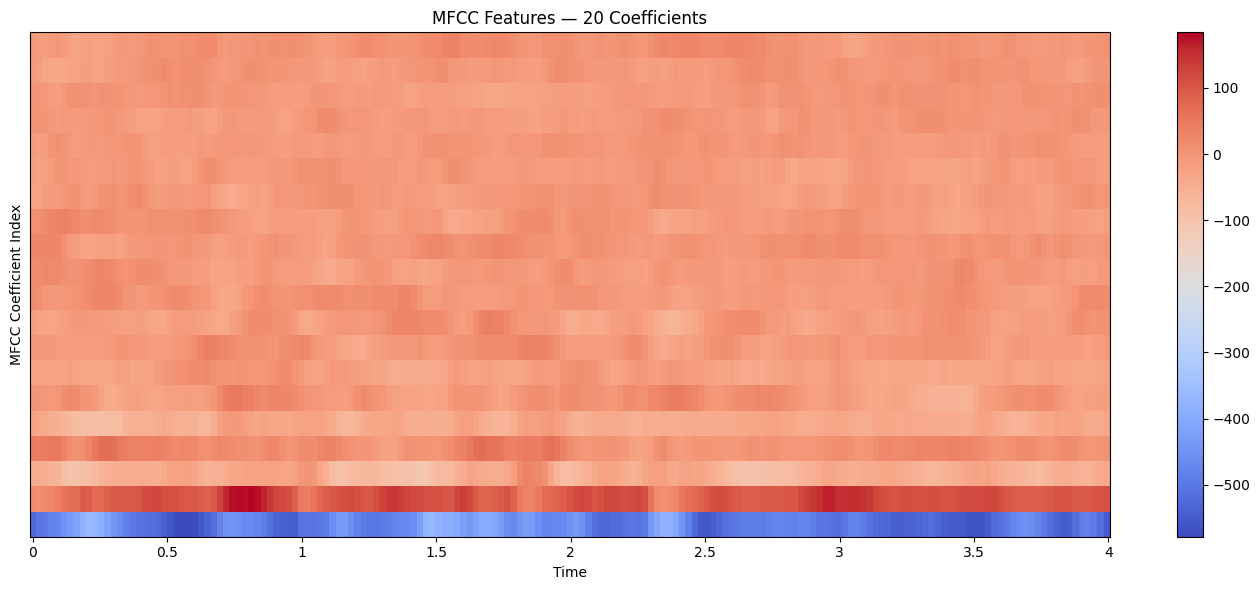

In [17]:

plt.figure(figsize=(14, 6))
librosa.display.specshow(
    mfcc,
    sr=TARGET_SR,
    hop_length=HOP_LENGTH,
    x_axis="time"
)
plt.colorbar()
plt.title(f"MFCC Features — {N_MFCC} Coefficients")
plt.ylabel("MFCC Coefficient Index")
plt.tight_layout()
plt.show()


### Mean MFCC Coefficients

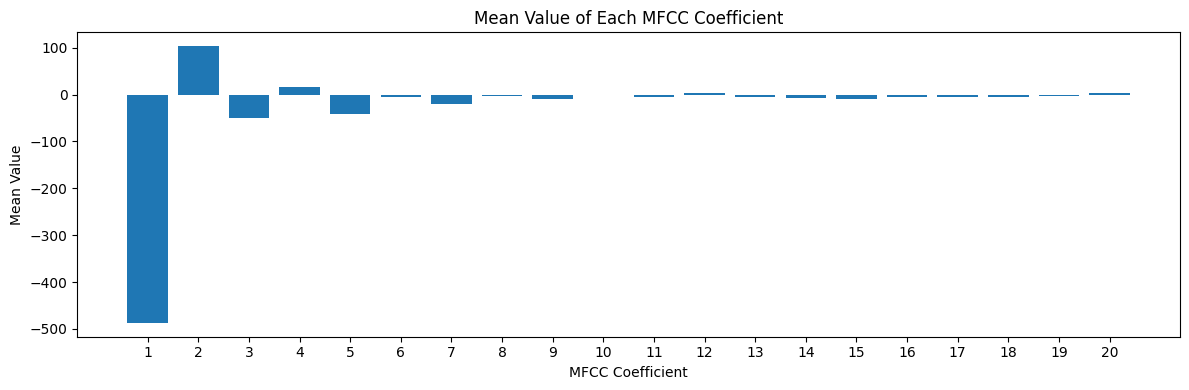

In [18]:

mfcc_mean = mfcc.mean(axis=1)

plt.figure(figsize=(12, 4))
plt.bar(np.arange(1, N_MFCC + 1), mfcc_mean)
plt.title("Mean Value of Each MFCC Coefficient")
plt.xlabel("MFCC Coefficient")
plt.ylabel("Mean Value")
plt.xticks(np.arange(1, N_MFCC + 1))
plt.tight_layout()
plt.show()


## **Step 10 — Display Sample Numerical Values**

In [19]:

# Sample waveform values
sample_count = 15

audio_samples_df = pd.DataFrame({
    "Sample index": np.arange(sample_count),
    "Original audio": y[:sample_count],
    "Noise-reduced audio": y_reduced[:sample_count]
})

print("First 15 waveform samples:")
display(audio_samples_df)

# First 5 MFCC coefficients across the first 10 frames
mfcc_sample_df = pd.DataFrame(
    mfcc[:5, :10],
    index=[f"MFCC_{i+1}" for i in range(5)],
    columns=[f"Frame_{j+1}" for j in range(10)]
)

print("\nSample MFCC values (first 5 coefficients × first 10 frames):")
display(mfcc_sample_df.round(4))


First 15 waveform samples:


,Sample index,Original audio,Noise-reduced audio
0,0,0.006553,0.002504
1,1,0.006657,0.002395
2,2,0.006030,0.002106
3,3,0.004788,0.001688
4,4,0.003141,0.001063
5,5,0.001181,0.000259
6,6,-0.000771,-0.000496
7,7,-0.002388,-0.001090
8,8,-0.003731,-0.001580
9,9,-0.004945,-0.002039



Sample MFCC values (first 5 coefficients × first 10 frames):


,Frame_1,Frame_2,Frame_3,Frame_4,Frame_5,Frame_6,Frame_7,Frame_8,Frame_9,Frame_10
MFCC_1,-526.647400,-503.744598,-495.450592,-481.502411,-474.826691,-448.459106,-430.728210,-420.078308,-384.843109,-359.112915
MFCC_2,18.698799,12.196600,18.060101,30.979300,39.592701,57.829102,64.378799,69.855003,96.982498,91.110703
MFCC_3,-47.923599,-44.412701,-46.994301,-56.786201,-65.932999,-84.995697,-97.438301,-97.673599,-90.066399,-86.205002
MFCC_4,47.119701,42.613701,45.648102,50.056301,52.800900,32.838799,15.326300,7.235500,13.467100,30.874300
MFCC_5,-22.106600,-31.433201,-39.304901,-48.298901,-53.643398,-58.535801,-66.222298,-79.457199,-82.667801,-83.260201


## **Step 11 — Save the Processed Audio and Extracted Features**

In [20]:

# 1. Save the noise-reduced audio
processed_audio_path = OUTPUT_DIR / "noise_reduced_sample.wav"
sf.write(processed_audio_path, y_reduced, sr)

# 2. Save complete MFCC matrix for the selected audio file
mfcc_npy_path = OUTPUT_DIR / "sample_mfcc_matrix.npy"
np.save(mfcc_npy_path, mfcc)

# 3. Save a fixed-length MFCC summary vector (mean + standard deviation)
mfcc_summary = {}
for i in range(N_MFCC):
    mfcc_summary[f"mfcc_{i+1}_mean"] = float(mfcc[i].mean())
    mfcc_summary[f"mfcc_{i+1}_std"] = float(mfcc[i].std())

mfcc_summary.update({
    "clip_id": sample_clip_id,
    "class_id": class_id,
    "class_label": class_label,
    "fold": fold,
    "original_sr": sr,
    "duration_seconds": duration
})

summary_df = pd.DataFrame([mfcc_summary])
summary_csv_path = OUTPUT_DIR / "sample_mfcc_summary.csv"
summary_df.to_csv(summary_csv_path, index=False)

print("Saved:")
print(" -", processed_audio_path)
print(" -", mfcc_npy_path)
print(" -", summary_csv_path)

display(summary_df.head())


Saved:
 - /content/experiment3_outputs/noise_reduced_sample.wav
 - /content/experiment3_outputs/sample_mfcc_matrix.npy
 - /content/experiment3_outputs/sample_mfcc_summary.csv


,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,mfcc_5_mean,mfcc_5_std,...,mfcc_19_mean,mfcc_19_std,mfcc_20_mean,mfcc_20_std,clip_id,class_id,class_label,fold,original_sr,duration_seconds
0,-487.161133,49.474895,103.342308,32.603935,-49.881649,26.603924,17.04015,20.06085,-40.674431,15.567327,...,-2.976832,11.367728,4.466913,12.91112,135776-2-0-49,2,children_playing,1,48000,4.0



## **Step 12 — Optional: Extract MFCC Features from Many / All UrbanSound8K Files**

For a future sound-recognition classifier, each audio clip needs a fixed-length feature vector. The code below:

1. Loads each audio file at its native sampling rate.
2. Converts stereo to mono if required.
3. Applies noise reduction.
4. Resamples to 22,050 Hz.
5. Extracts 20 MFCCs.
6. Stores the **mean and standard deviation** of every MFCC coefficient.
7. Preserves the UrbanSound8K **fold**, **class ID** and **class label**.

By default the notebook processes a smaller subset for a quick lab demonstration.  
Set `RUN_FULL_BATCH = True` to process all 8,732 files.


In [21]:

RUN_FULL_BATCH = False
DEMO_BATCH_LIMIT = 250  # used only when RUN_FULL_BATCH=False

def extract_fixed_mfcc_features(clip):
    signal, native_sr = librosa.load(clip.audio_path, sr=None, mono=True)

    # Skip invalid/empty signals.
    if signal is None or len(signal) == 0:
        return None

    # Noise reduction
    reduced = nr.reduce_noise(
        y=signal,
        sr=native_sr,
        stationary=False,
        prop_decrease=0.8
    ).astype(np.float32)

    # Consistent sample rate for MFCCs
    if native_sr != TARGET_SR:
        reduced = librosa.resample(reduced, orig_sr=native_sr, target_sr=TARGET_SR)

    feature_mfcc = librosa.feature.mfcc(
        y=reduced,
        sr=TARGET_SR,
        n_mfcc=N_MFCC,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH
    )

    row = {
        "clip_id": clip.clip_id,
        "fold": clip.fold,
        "class_id": clip.class_id,
        "class_label": clip.class_label,
        "native_sr": native_sr,
        "duration_seconds": librosa.get_duration(y=signal, sr=native_sr)
    }

    # Fixed-length representation: 20 means + 20 standard deviations = 40 MFCC features
    for i in range(N_MFCC):
        row[f"mfcc_{i+1}_mean"] = float(feature_mfcc[i].mean())
        row[f"mfcc_{i+1}_std"] = float(feature_mfcc[i].std())

    return row


clip_ids_for_batch = list(dataset.clip_ids)
if not RUN_FULL_BATCH:
    clip_ids_for_batch = clip_ids_for_batch[:DEMO_BATCH_LIMIT]

print("Files selected for batch feature extraction:", len(clip_ids_for_batch))

feature_rows = []
failed_files = []

for clip_id in tqdm(clip_ids_for_batch):
    try:
        clip = dataset.clip(clip_id)
        row = extract_fixed_mfcc_features(clip)
        if row is not None:
            feature_rows.append(row)
    except Exception as e:
        failed_files.append((clip_id, str(e)))

features_df = pd.DataFrame(feature_rows)

batch_csv_path = OUTPUT_DIR / "urbansound8k_mfcc_features.csv"
features_df.to_csv(batch_csv_path, index=False)

print("\nFeature table shape:", features_df.shape)
print("Saved feature table:", batch_csv_path)
print("Failed files:", len(failed_files))

display(features_df.head())


Files selected for batch feature extraction: 250


  0%|          | 0/250 [00:00<?, ?it/s]


Feature table shape: (250, 46)
Saved feature table: /content/experiment3_outputs/urbansound8k_mfcc_features.csv
Failed files: 0


,clip_id,fold,class_id,class_label,native_sr,duration_seconds,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,...,mfcc_16_mean,mfcc_16_std,mfcc_17_mean,mfcc_17_std,mfcc_18_mean,mfcc_18_std,mfcc_19_mean,mfcc_19_std,mfcc_20_mean,mfcc_20_std
0,135776-2-0-49,1,2,children_playing,48000,4.000000,-487.161133,49.474895,103.342308,32.603935,...,-4.198981,7.540500,-5.605062,9.366148,-4.557063,10.619449,-2.976832,11.367728,4.466913,12.911120
1,46654-6-0-0,1,6,gun_shot,44100,1.138503,-183.741760,97.354660,82.741241,45.656853,...,1.210961,8.942719,0.854150,10.372403,-4.035457,6.453122,3.033879,7.681418,-4.979239,6.372850
2,57320-0-0-24,1,0,air_conditioner,44100,4.000000,-325.242859,48.917736,69.686584,18.100466,...,13.129127,5.901331,5.584692,8.167747,12.704342,6.608742,-0.310970,6.588295,4.775897,6.436149
3,134717-0-0-26,1,0,air_conditioner,44100,4.000000,-329.844299,14.090865,179.454636,9.167654,...,-7.001035,3.503387,-14.502058,4.262266,-2.916180,3.483534,-0.753893,3.528714,1.041924,3.870822
4,174276-7-5-0,1,7,jackhammer,44100,2.870000,-220.860275,21.776255,40.685863,6.614061,...,5.693271,3.638031,-3.001277,5.548912,4.399506,4.912696,-0.255617,4.266728,-0.016525,5.477113


### Verify Class and Fold Information in the Saved Feature Table

In [22]:

if not features_df.empty:
    print("Class distribution in processed subset:")
    display(features_df["class_label"].value_counts().rename_axis("class").reset_index(name="count"))

    print("\nFold distribution in processed subset:")
    display(features_df["fold"].value_counts().sort_index().rename_axis("fold").reset_index(name="count"))


Class distribution in processed subset:


,class,count
0,jackhammer,59
1,dog_bark,32
2,siren,26
3,street_music,26
4,air_conditioner,24
5,children_playing,24
6,drilling,22
7,engine_idling,21
8,gun_shot,11
9,car_horn,5



Fold distribution in processed subset:


,fold,count
0,1,250


## **Step 13 — Package Experiment Outputs for Download**

In [23]:

import shutil

zip_base = "/content/Experiment_3_outputs"
zip_path = shutil.make_archive(zip_base, "zip", OUTPUT_DIR)

print("Created ZIP:", zip_path)
print("Files available in output directory:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p.name)


Created ZIP: /content/Experiment_3_outputs.zip
Files available in output directory:
 - noise_reduced_sample.wav
 - sample_mfcc_matrix.npy
 - sample_mfcc_summary.csv
 - urbansound8k_mfcc_features.csv



## **Observations / Result**

- The UrbanSound8K waveform was successfully loaded and analyzed in both the **time domain** and **frequency domain**.
- The experiment measured **signal duration**, **native sampling rate**, **number of samples**, **waveform shape**, amplitude statistics and spectral characteristics.
- The FFT and log-frequency spectrogram revealed the distribution of frequency energy over the recording.
- Noise reduction was applied using spectral gating, and the original and processed signals were compared using:
  - time-domain waveforms,
  - frequency spectra,
  - log-frequency spectrograms,
  - RMS and spectral statistics.
- The processed signal was resampled to a common **22,050 Hz** sampling rate for consistent feature extraction.
- **20 MFCC coefficients** were extracted and visualized as a time-dependent heatmap.
- Sample numerical values of the original waveform, noise-reduced waveform and MFCC matrix were displayed.
- The processed audio, complete MFCC matrix and fixed-length MFCC feature summaries were saved for future audio/sound recognition tasks.

### Conclusion
The audio preprocessing pipeline successfully converts raw environmental sound into cleaner, structured acoustic features. Noise reduction suppresses unwanted components, while MFCCs provide a compact representation of the sound's spectral envelope that can be used as input to machine-learning or deep-learning models for urban sound classification.

### Important Note for Future Classification
UrbanSound8K provides predefined folds. For academically valid classifier evaluation, preserve these folds rather than creating a random train/test split.



## **Reference**
J. Salamon, C. Jacoby and J. P. Bello, *A Dataset and Taxonomy for Urban Sound Research*, Proceedings of the 22nd ACM International Conference on Multimedia, 2014.

Dataset website: https://urbansounddataset.weebly.com/urbansound8k.html
